# Unstructured-grid access patterns

How can dynamical.org best structure datasets whose horizontal spatial dimensions don't follow a 2D grid? For example, grids like reduced gaussian (e.g. ECMWF IFS), icosahedral (e.g. DWD ICON), and HEALPix. This notebook explores common usage patterns and open source library interoperability using a draft dataset structure + metadata applied to a real world dataset, DWD's ICON-EU. Our goal is to make the user experience as simple as possible by following existing conventions.

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install dynamical-catalog 'xarray>=2026.2' matplotlib cartopy shapely scipy 'uxarray>=2026.10.1'

In [2]:
# In staging for feedback, structure may change in breaking ways before promotion to prod.
import os
os.environ.setdefault("DYNAMICAL_STAC_CATALOG_URL", "https://stac-staging.dynamical.org/catalog.json")

import dynamical_catalog

ds = dynamical_catalog.open("dwd-icon-eu-forecast-5-day-icosahedral", chunks=None)
ds

<xarray.Dataset> Size: 956GB
Dimensions:                                             (init_time: 176,
                                                         lead_time: 93,
                                                         cell: 768608)
Coordinates:
  * init_time                                           (init_time) datetime64[ns] 1kB ...
    ingested_forecast_length                            (init_time) timedelta64[us] 1kB ...
    expected_forecast_length                            (init_time) timedelta64[us] 1kB ...
  * lead_time                                           (lead_time) timedelta64[us] 744B ...
    valid_time                                          (init_time, lead_time) datetime64[ns] 131kB ...
  * cell                                                (cell) int32 3MB 0 .....
    latitude                                            (cell) float32 3MB ...
    longitude                                           (cell) float32 3MB ...
    spatial_ref                                         int64 8B ...
Data variables: (12/19)
    cloud_cover_low                                     (init_time, lead_time, cell) float32 50GB ...
    convective_available_potential_energy_atmosphere    (init_time, lead_time, cell) float32 50GB ...
    dew_point_temperature_2m                            (init_time, lead_time, cell) float32 50GB ...
    downward_direct_short_wave_radiation_flux_surface   (init_time, lead_time, cell) float32 50GB ...
    downward_diffuse_short_wave_radiation_flux_surface  (init_time, lead_time, cell) float32 50GB ...
    cloud_cover_high                                    (init_time, lead_time, cell) float32 50GB ...
    ...                                                  ...
    temperature_2m                                      (init_time, lead_time, cell) float32 50GB ...
    total_cloud_cover_atmosphere                        (init_time, lead_time, cell) float32 50GB ...
    pressure_surface                                    (init_time, lead_time, cell) float32 50GB ...
    wind_gust_10m                                       (init_time, lead_time, cell) float32 50GB ...
    wind_u_10m                                          (init_time, lead_time, cell) float32 50GB ...
    wind_v_10m                                          (init_time, lead_time, cell) float32 50GB ...
Attributes:
    dataset_id:           dwd-icon-eu-forecast-5-day-icosahedral
    dataset_version:      0.1.0
    name:                 DWD ICON-EU forecast, 5 day, icosahedral
    description:          High-resolution weather forecasts for Europe from t...
    attribution:          DWD ICON-EU data processed by dynamical.org.
    license:              CC-BY-4.0
    spatial_domain:       Europe
    spatial_resolution:   6.5 km
    time_domain:          Forecasts initialized 2026-10-07 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-120 hours (0-5 days) ahead
    forecast_resolution:  Forecast step 0-78 hours: hourly, 81-120 hours: 3 h...

## 1. Point selection

### 1a. xarray

Quick and simple. Only drawback is distance is in degrees, not meters. In most cases that's equivalent for this purpose.

In [3]:
import xarray as xr

ds = ds.set_xindex(("latitude", "longitude"), xr.indexes.NDPointIndex)
ds.sel(latitude=38, longitude=-9, method="nearest")

<xarray.Dataset> Size: 1MB
Dimensions:                                             (init_time: 176,
                                                         lead_time: 93)
Coordinates:
  * init_time                                           (init_time) datetime64[ns] 1kB ...
    ingested_forecast_length                            (init_time) timedelta64[us] 1kB ...
    expected_forecast_length                            (init_time) timedelta64[us] 1kB ...
  * lead_time                                           (lead_time) timedelta64[us] 744B ...
    valid_time                                          (init_time, lead_time) datetime64[ns] 131kB ...
    cell                                                int32 4B 481735
    spatial_ref                                         int64 8B ...
    latitude                                            float32 4B 38.01
    longitude                                           float32 4B -9.008
Data variables: (12/19)
    cloud_cover_low                                     (init_time, lead_time) float32 65kB ...
    convective_available_potential_energy_atmosphere    (init_time, lead_time) float32 65kB ...
    dew_point_temperature_2m                            (init_time, lead_time) float32 65kB ...
    downward_direct_short_wave_radiation_flux_surface   (init_time, lead_time) float32 65kB ...
    downward_diffuse_short_wave_radiation_flux_surface  (init_time, lead_time) float32 65kB ...
    cloud_cover_high                                    (init_time, lead_time) float32 65kB ...
    ...                                                  ...
    temperature_2m                                      (init_time, lead_time) float32 65kB ...
    total_cloud_cover_atmosphere                        (init_time, lead_time) float32 65kB ...
    pressure_surface                                    (init_time, lead_time) float32 65kB ...
    wind_gust_10m                                       (init_time, lead_time) float32 65kB ...
    wind_u_10m                                          (init_time, lead_time) float32 65kB ...
    wind_v_10m                                          (init_time, lead_time) float32 65kB ...
Attributes:
    dataset_id:           dwd-icon-eu-forecast-5-day-icosahedral
    dataset_version:      0.1.0
    name:                 DWD ICON-EU forecast, 5 day, icosahedral
    description:          High-resolution weather forecasts for Europe from t...
    attribution:          DWD ICON-EU data processed by dynamical.org.
    license:              CC-BY-4.0
    spatial_domain:       Europe
    spatial_resolution:   6.5 km
    time_domain:          Forecasts initialized 2026-10-07 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-120 hours (0-5 days) ahead
    forecast_resolution:  Forecast step 0-78 hours: hourly, 81-120 hours: 3 h...

### 1b. UXarray

Find the face containing the point on the sphere; this requires the mesh.

In [4]:
import uxarray as ux

mesh = dynamical_catalog.open("dwd-icon-eu-forecast-5-day-icosahedral", group="mesh", chunks=None)
uxgrid = ux.open_grid(mesh)
point_faces = uxgrid.get_faces_containing_point((-9, 38), return_counts=False)[0]
ds.isel(cell=point_faces)

<xarray.Dataset> Size: 1MB
Dimensions:                                             (init_time: 176,
                                                         lead_time: 93, cell: 1)
Coordinates:
  * init_time                                           (init_time) datetime64[ns] 1kB ...
    ingested_forecast_length                            (init_time) timedelta64[us] 1kB ...
    expected_forecast_length                            (init_time) timedelta64[us] 1kB ...
  * lead_time                                           (lead_time) timedelta64[us] 744B ...
    valid_time                                          (init_time, lead_time) datetime64[ns] 131kB ...
  * cell                                                (cell) int32 4B 481735
    latitude                                            (cell) float32 4B 38.01
    longitude                                           (cell) float32 4B -9.008
    spatial_ref                                         int64 8B ...
Data variables: (12/19)
    cloud_cover_low                                     (init_time, lead_time, cell) float32 65kB ...
    convective_available_potential_energy_atmosphere    (init_time, lead_time, cell) float32 65kB ...
    dew_point_temperature_2m                            (init_time, lead_time, cell) float32 65kB ...
    downward_direct_short_wave_radiation_flux_surface   (init_time, lead_time, cell) float32 65kB ...
    downward_diffuse_short_wave_radiation_flux_surface  (init_time, lead_time, cell) float32 65kB ...
    cloud_cover_high                                    (init_time, lead_time, cell) float32 65kB ...
    ...                                                  ...
    temperature_2m                                      (init_time, lead_time, cell) float32 65kB ...
    total_cloud_cover_atmosphere                        (init_time, lead_time, cell) float32 65kB ...
    pressure_surface                                    (init_time, lead_time, cell) float32 65kB ...
    wind_gust_10m                                       (init_time, lead_time, cell) float32 65kB ...
    wind_u_10m                                          (init_time, lead_time, cell) float32 65kB ...
    wind_v_10m                                          (init_time, lead_time, cell) float32 65kB ...
Attributes:
    dataset_id:           dwd-icon-eu-forecast-5-day-icosahedral
    dataset_version:      0.1.0
    name:                 DWD ICON-EU forecast, 5 day, icosahedral
    description:          High-resolution weather forecasts for Europe from t...
    attribution:          DWD ICON-EU data processed by dynamical.org.
    license:              CC-BY-4.0
    spatial_domain:       Europe
    spatial_resolution:   6.5 km
    time_domain:          Forecasts initialized 2026-10-07 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-120 hours (0-5 days) ahead
    forecast_resolution:  Forecast step 0-78 hours: hourly, 81-120 hours: 3 h...

## 2. Bounding box

In [5]:
field = ds["temperature_2m"].sel(init_time="2026-11-10T00", lead_time="12h").load()

### 2a. xarray

Quick and simple. Select cells by their centres, so boundary cells can extend outside the box.

In [6]:
box = field.isel(cell=(
    (field.longitude >= -10) & (field.longitude <= -6)
    & (field.latitude >= 37) & (field.latitude <= 42.5)
))
box

<xarray.DataArray 'temperature_2m' (cell: 4718)> Size: 19kB
array([20.375 , 20.25  , 20.375 , ..., 12.625 , 13.5625, 13.1875],
      shape=(4718,), dtype=float32)
Coordinates:
  * cell                      (cell) int32 19kB 411173 411174 ... 512750 512751
    latitude                  (cell) float32 19kB 37.53 37.62 ... 42.04 42.06
    longitude                 (cell) float32 19kB -9.981 -9.94 ... -7.478 -7.543
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    lead_time                 timedelta64[us] 8B 12:00:00
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

### 2b. UXarray

Select faces wholly inside the box; boundary-crossing faces are excluded.

In [7]:
uxfield = ux.UxDataArray(field.drop_indexes(("latitude", "longitude")).rename(cell="n_face"), uxgrid=uxgrid)
uxbox = uxfield.subset.bounding_box((-10, -6), (37, 42.5))
uxbox

<xarray.UxDataArray 'temperature_2m' (n_face: 4517)> Size: 18kB
array([20.25  , 20.    , 19.875 , ..., 12.625 , 13.5625, 13.1875],
      shape=(4517,), dtype=float32)
Coordinates:
  * n_face                    (n_face) int32 18kB 411174 411185 ... 512751
    latitude                  (n_face) float32 18kB 37.62 37.7 ... 42.04 42.06
    longitude                 (n_face) float32 18kB -9.94 -9.899 ... -7.543
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    lead_time                 timedelta64[us] 8B 12:00:00
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

## 3. Map plotting

### 3a. Matplotlib

Triangulate the selected cell centres; the triangles differ from the native faces.

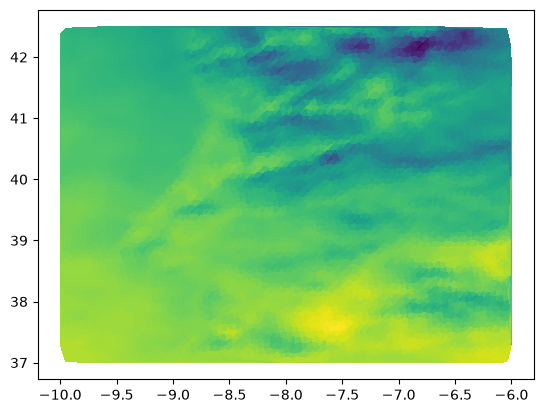

In [8]:
import matplotlib.pyplot as plt

plt.tripcolor(box.longitude, box.latitude, box);

### 3b. UXarray

Draw native polygons for the same centre-selected cells; Matplotlib needs an explicit collection and transform.

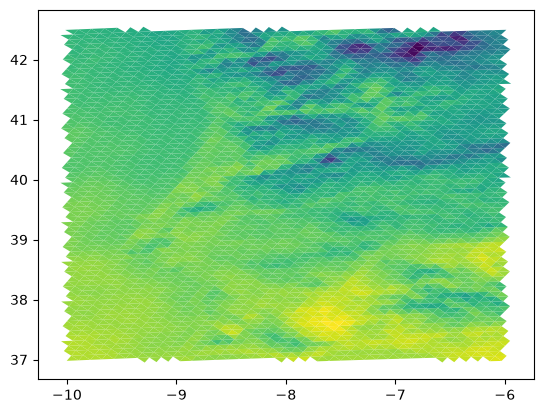

In [9]:
polygons = uxfield.isel(n_face=box.cell.values).to_polycollection()
polygons.set_transform(plt.gca().transData)
plt.gca().add_collection(polygons)
plt.autoscale()

## 4. Arbitrary geometry means

### 4a. Shapely and xarray

Average cells whose centres lie in a coarse polygon around mainland Portugal; cells are not clipped at its edges.

In [10]:
import shapely

mainland = shapely.Polygon([
    (-9.5, 38.7), (-8.9, 41.9), (-6.2, 41.9), (-7.5, 39.7), (-7.4, 37), (-8.9, 37),
])
polygon_cells = shapely.contains_xy(mainland, field.longitude.values, field.latitude.values)
polygon = field.isel(cell=polygon_cells)
unweighted = polygon.mean("cell", keep_attrs=True)
unweighted

<xarray.DataArray 'temperature_2m' ()> Size: 4B
array(17.983597, dtype=float32)
Coordinates:
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    lead_time                 timedelta64[us] 8B 12:00:00
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

### 4b. UXarray

Weight the same centre-selected cells by spherical face area; the polygon mask still comes from Shapely.

In [11]:
uxpolygon = uxfield.isel(n_face=polygon_cells)
weighted = uxpolygon.weighted(uxpolygon.uxgrid.face_areas).mean("n_face", keep_attrs=True)
weighted

<xarray.UxDataArray 'temperature_2m' ()> Size: 8B
array(17.98047205)
Coordinates:
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    lead_time                 timedelta64[us] 8B 12:00:00
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

## 5. Regridding (remapping)

### 5a. xarray

Quick nearest-neighbour remapping; assign the target coordinates because selection returns source centres.

In [12]:
import numpy as np

target = xr.Dataset(coords={
    "latitude": np.arange(37, 42.51, 0.1),
    "longitude": np.arange(-10, -5.99, 0.1),
})
regular = field.sel(latitude=target.latitude, longitude=target.longitude, method="nearest")
regular = regular.assign_coords(target.coords)
regular

<xarray.DataArray 'temperature_2m' (latitude: 56, longitude: 41)> Size: 9kB
array([[20.625 , 20.625 , 20.625 , ..., 21.25  , 21.625 , 21.625 ],
       [20.625 , 20.75  , 20.625 , ..., 21.5   , 21.375 , 21.5   ],
       [20.75  , 20.625 , 20.625 , ..., 21.5   , 21.25  , 21.375 ],
       ...,
       [17.375 , 17.25  , 17.125 , ..., 12.3125, 13.75  , 14.125 ],
       [17.25  , 17.    , 17.125 , ..., 12.8125, 13.6875, 14.3125],
       [17.    , 17.    , 17.    , ..., 12.875 , 13.4375, 13.625 ]],
      shape=(56, 41), dtype=float32)
Coordinates:
  * latitude                  (latitude) float64 448B 37.0 37.1 ... 42.4 42.5
  * longitude                 (longitude) float64 328B -10.0 -9.9 ... -6.1 -6.0
    cell                      (latitude, longitude) int32 9kB 481336 ... 469280
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    lead_time                 timedelta64[us] 8B 12:00:00
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

### 5b. UXarray

Interpolate from four nearby centres using spherical distances; restoring the target dimensions takes an explicit reshape.

In [13]:
target_mesh = ux.Grid.from_structured(lon=target.longitude.values, lat=target.latitude.values)
interpolated = uxfield.remap.inverse_distance_weighted(target_mesh, k=4)
smooth = xr.DataArray(
    interpolated.values.reshape(target.sizes["latitude"], target.sizes["longitude"]),
    dims=("latitude", "longitude"), coords=target.coords, attrs={"long_name": field.long_name, "units": field.units},
)
smooth

<xarray.DataArray (latitude: 56, longitude: 41)> Size: 18kB
array([[20.625     , 20.625     , 20.625     , ..., 21.27196756,
        21.59141795, 21.63067196],
       [20.68543506, 20.69504498, 20.625     , ..., 21.5       ,
        21.4130053 , 21.50611048],
       [20.72520196, 20.64630814, 20.625     , ..., 21.39389414,
        21.27678194, 21.2260898 ],
       ...,
       [17.39201974, 17.21873889, 17.14405038, ..., 12.39887482,
        13.62807383, 14.14294038],
       [17.22047797, 17.07218224, 17.04034142, ..., 13.1799965 ,
        13.76566532, 14.0578482 ],
       [17.08822697, 17.03367604, 16.94650942, ..., 12.47755193,
        13.62854741, 13.93308791]], shape=(56, 41))
Coordinates:
  * latitude   (latitude) float64 448B 37.0 37.1 37.2 37.3 ... 42.3 42.4 42.5
  * longitude  (longitude) float64 328B -10.0 -9.9 -9.8 -9.7 ... -6.2 -6.1 -6.0
Attributes:
    long_name:  2 metre temperature
    units:      degree_Celsius